[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/halla-ai/intronlp-2026/blob/main/notebooks/week-09.ipynb)

# 9주차 실습: 문맥을 참고하는 위치 관찰

- 목표: 실제 사전학습 모델의 어텐션 가중치와 사람이 고른 참조 위치 비교
- 실행: CPU만 사용, 기본값 그대로 모두 실행 가능
- 수정: 선택 활동으로 2의 TODO 한 지점만 변경, 필수 코드 작성 없음
- 교육용 모형 문장: 제주를 배경으로 작성한 설명용 예시
- 실제 모델 문장: 제주관광공사 공개 한라산 페이지의 짧은 원문에 제목 추가 및 빈칸 치환, 운영 정보 검증 용도 아님
- 모델: `prajjwal1/bert-tiny`, MIT. 영어 사전학습 BERT 계열의 작은 모델, 한국어 이해 능력 평가에 사용하지 않음
- 출처: https://huggingface.co/prajjwal1/bert-tiny

## 0. 준비

설치 오류가 나도 다음 셀에서 교육용 모형 관찰 가능. 교육용 모형은 실제 모델 결과가 아님. 설치·다운로드에 성공하면 실제 모델로 어텐션과 빈칸 후보 출력. GPU로 변경할 필요 없음.

In [1]:
import os
import subprocess
import sys
os.environ["HF_HUB_ETAG_TIMEOUT"] = "15"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "30"
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "torch>=2.6,<3", "transformers>=4.40,<5",
                    "matplotlib>=3.7,<4"], check=True, timeout=300)
    print("설치 완료")
except Exception as error:
    print("설치 실패, 교육용 모형으로 계속 실행:", type(error).__name__)

설치 완료


## 1-1. 학습하지 않은 교육용 어텐션

사람이 지정한 가중치로 참고 비중의 구조만 관찰. `그것은`의 행에서 `우산을`이 크게 보이도록 직접 지정한 값. 모델이 대명사의 뜻을 이해한 증거가 아님. 모든 행의 합은 1이며, 그림의 가로가 참고하는 토큰, 세로가 현재 토큰.

교육용 모형: 사람이 지정한 값
0 민지는
1 제주에서
2 우산을
3 샀다
4 그것은
5 빨갛다
행=현재 위치, 열=참고 위치


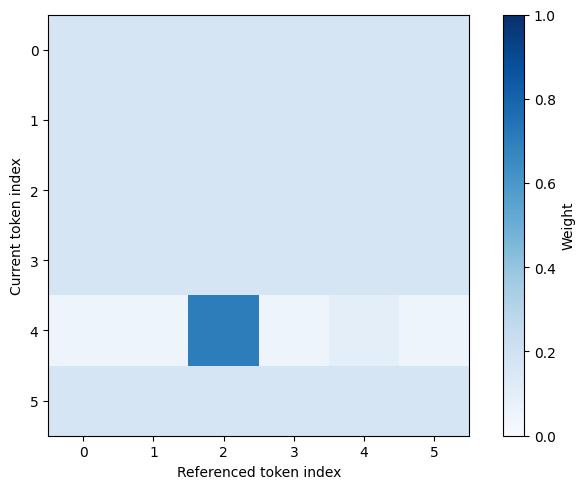

In [2]:
import math

toy_tokens = ["민지는", "제주에서", "우산을", "샀다", "그것은", "빨갛다"]
toy_weights = [[1 / len(toy_tokens)] * len(toy_tokens) for _ in toy_tokens]
toy_weights[4] = [0.05, 0.05, 0.70, 0.05, 0.10, 0.05]

def show_matrix(tokens, weights, title):
    # 영어 위치 번호를 축에 사용: 한국어 폰트 미설치 환경에서도 깨짐 방지
    print(title)
    for i, token in enumerate(tokens):
        print(i, token)
    print("행=현재 위치, 열=참고 위치")
    try:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(7, 5))
        plot = ax.imshow(weights, vmin=0, vmax=1, cmap="Blues")
        ax.set_xticks(range(len(tokens)))
        ax.set_yticks(range(len(tokens)))
        ax.set_xlabel("Referenced token index")
        ax.set_ylabel("Current token index")
        fig.colorbar(plot, ax=ax, label="Weight")
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    except ImportError:
        print("그림 라이브러리 없음: 숫자 표로 확인")
        for row in weights:
            print(" ".join(f"{value:.2f}" for value in row))

show_matrix(toy_tokens, toy_weights, "교육용 모형: 사람이 지정한 값")

## 1-2. 작은 사전학습 모델 준비

모델을 새로 학습하지 않고 공개 가중치 사용. `eval()`로 dropout 해제, `no_grad()`로 학습 계산 제외. eager 구현은 어텐션 행렬 출력을 위한 설정. 실패하면 실제 모델 관찰을 건너뛰며, 교육용 모형 결과만 제출할 경우 실패 사실 기록.

In [3]:
model = None
tokenizer = None
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForMaskedLM
    torch.set_num_threads(2)
    model_name = "prajjwal1/bert-tiny"
    revision = "6f75de8b60a9f8a2fdf7b69cbd86d9e64bcb3837"
    tokenizer = AutoTokenizer.from_pretrained(model_name, revision=revision)
    model = AutoModelForMaskedLM.from_pretrained(model_name, revision=revision, attn_implementation="eager")
    model.to("cpu")
    model.eval()
    print("실제 사전학습 모델 준비 완료:", model_name)
    print("층:", model.config.num_hidden_layers, "헤드:", model.config.num_attention_heads)
except Exception as error:
    model = None
    print("실제 모델 사용 불가:", type(error).__name__)
    print("교육용 모형만 계속 사용. 연결 복구 후 이 셀부터 다시 실행 가능")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/17.8M [00:00<?, ?B/s]

실제 사전학습 모델 준비 완료: prajjwal1/bert-tiny
층: 2 헤드: 2


## 1-3. 실제 모델의 참고 비중과 빈칸 후보

제주관광공사 공개 원문 기반 입력. 출처: [Hallasan](https://www.visitjeju.net/en/detail/view?contentsid=CONT_000000000500685), 열람일 2026-10-11.

원문 짧은 발췌: 'At 1,950 m above sea level, it is the highest mountain in South Korea.'

페이지 제목 `Hallasan.`을 앞에 붙이고 `highest`를 `[MASK]`로 치환. `it`이 가리키는 한라산과 실제 참고 비중 비교. 교육용 모형의 우산 문장과 출처·가중치 구분.

- 마지막 층의 첫 헤드 관찰, 헤드 평균 아님
- 특수 토큰과 WordPiece 조각도 그림에 포함
- `it` 행에서 큰 가중치 위치와 사람이 고른 `Hallasan`의 토큰 위치 비교
- 가중치는 정답 확률이나 원인의 증명 아님. 빈칸 확률도 실제 사실의 확률 아님

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

실제 사전학습 모델: 마지막 층, 첫 헤드
0 [CLS]
1 hall
2 ##asa
3 ##n
4 .
5 at
6 1
7 ,
8 950
9 m
10 above
11 sea
12 level
13 ,
14 it
15 is
16 the
17 [MASK]
18 mountain
19 in
20 south
21 korea
22 .
23 [SEP]
행=현재 위치, 열=참고 위치


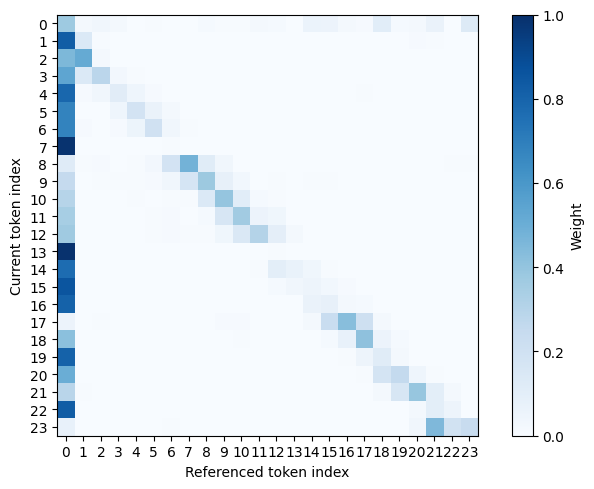

it의 참고 비중 상위 위치:
0 [CLS] 0.768
12 level 0.101
13 , 0.068
14 it 0.037
15 is 0.007
빈칸 후보(전체 어휘 분포에서의 확률):
largest 0.159
highest 0.109
tallest 0.044
oldest 0.035
mountain 0.030


In [4]:
def inspect_text(text):
    if model is None:
        print("실제 모델 관찰 생략, 교육용 모형 결과")
        show_matrix(toy_tokens, toy_weights, "교육용 모형: 미학습, 직접 지정한 값")
        print("빈칸 후보 없음: 실제 모델이 필요")
        return
    if text.count("[MASK]") != 1:
        print("[MASK]를 정확히 한 번 포함한 문장 필요")
        return
    inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=64)
    mask_positions = (inputs["input_ids"][0] == tokenizer.mask_token_id).nonzero(as_tuple=True)[0]
    if len(mask_positions) != 1:
        print("빈칸이 길이 제한 뒤에 있음: 문장을 짧게 변경 필요")
        return
    with torch.no_grad():
        output = model(**inputs, output_attentions=True)
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    weights = output.attentions[-1][0, 0].cpu().tolist()
    show_matrix(tokens, weights, "실제 사전학습 모델: 마지막 층, 첫 헤드")
    if "it" in tokens:
        row = weights[tokens.index("it")]
        ranking = sorted(range(len(tokens)), key=lambda i: row[i], reverse=True)[:5]
        print("it의 참고 비중 상위 위치:")
        for i in ranking:
            print(i, tokens[i], f"{row[i]:.3f}")
    position = int(mask_positions[0])
    values, indices = output.logits[0, position].softmax(dim=-1).topk(5)
    print("빈칸 후보(전체 어휘 분포에서의 확률):")
    for value, index in zip(values.tolist(), indices.tolist()):
        print(tokenizer.convert_ids_to_tokens(index), f"{value:.3f}")

baseline = "Hallasan. At 1,950 m above sea level, it is the [MASK] mountain in South Korea."
inspect_text(baseline)

## 2. 한 지점만 바꾸기

기본값은 같은 공개 원문의 `mountain`을 `[MASK]`로 치환한 입력. TODO를 그대로 두어도 `highest`와 `mountain`을 가린 두 입력의 후보 비교 가능. 선택적으로 기존 입력 문장 한 곳만 교체. 영어 문장 사용, `[MASK]` 한 개 유지. 빈칸 위치와 문맥에 따라 후보 및 `it` 행의 참고 비중이 어떻게 달라지는지 관찰. 결과가 기대와 달라도 오류와 구별.

실제 사전학습 모델: 마지막 층, 첫 헤드
0 [CLS]
1 hall
2 ##asa
3 ##n
4 .
5 at
6 1
7 ,
8 950
9 m
10 above
11 sea
12 level
13 ,
14 it
15 is
16 the
17 highest
18 [MASK]
19 in
20 south
21 korea
22 .
23 [SEP]
행=현재 위치, 열=참고 위치


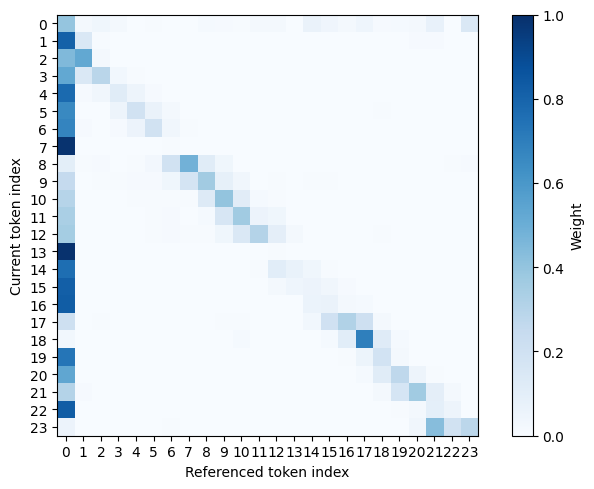

it의 참고 비중 상위 위치:
0 [CLS] 0.759
12 level 0.106
13 , 0.069
14 it 0.038
15 is 0.007
빈칸 후보(전체 어휘 분포에서의 확률):
peak 0.474
level 0.141
point 0.079
altitude 0.040
elevation 0.037


In [6]:
# TODO: 아래 문장 한 곳만 변경
student_text = "Hallasan. At 1,950 m above sea level, it is the highest [MASK] in South Korea."

inspect_text(student_text)

## 3. 확인 질문

1. 사람이 고른 대명사 `it`의 참조 대상 `Hallasan`의 토큰 위치와 실제 모델의 `it` 행 상위 위치 비교. 특수 토큰에 큰 비중이 나타나는지도 확인.
2. 원문과 수정 문장의 빈칸 후보 5개 비교. 확률을 사실의 확률로 읽을 수 없는 이유 설명.
3. 교육용 모형과 실제 모델 결과의 차이 설명. 실제 모델 사용 불가 시 오류 유형과 건너뛴 결과 기록.
4. 긴 제주 행정 안내에서 대상·기한·예외가 떨어져 있을 때 놓칠 수 있는 조건 하나 서술. 실제 정보는 reference/data.md의 공식 출처에서 확인.

답안: 아래 markdown 셀에 기록.

- 실행 모드(실제 모델 / 교육용 모형):prajjwal1/bert-tiny
- 참조 위치 비교: 대명사 it의 실제 지시 대상인 Hallasan(인덱스 1~3)에는 어텐션 비중이 거의 실리지 않았고, 대신 특수 토큰 [CLS](0.759 ~ 0.768)에 가장 많은 비중이 집중됨.

- 변경 전·후 빈칸 후보:

변경 전 ([MASK] mountain): largest (0.159), highest (0.109), tallest (0.044), oldest (0.035), mountain (0.030)

변경 후 (highest [MASK]): peak (0.474), level (0.141), point (0.079), altitude (0.040), elevation (0.037)

변경 전 문장은 마스크가 산 앞에 위치하여 산의 크기나 높이를 수식하는 형용사(largest, highest, tallest)가 주로 예측된 반면, 변경 후 문장은 최상급 표현 뒤에 위치하여 고도나 정상을 뜻하는 명사(peak, point, altitude)가 상위 후보로 나타난다.
- 어텐션 해석의 한계:어텐션 가중치는 토큰 간 연산 비중일 뿐 정답의 직접적 이유나 인과관계를 증명하는 근거가 아니며, 모델이 출력하는 빈칸 확률 또한 실제 세상의 객관적 사실(Fact) 발생 확률이 아니라 학습한 텍스트 통계 패턴에 따른 예측값에 불과하기 때문이다.
- 긴 문서의 조건 누락 사례:8월 1일부터 9월 30일까지 관음사 코스 삼각봉-백록담 구간이 통제된다는 예외 조건을 놓쳐, 통제 기간인데도 관음사 코스로 정상까지 갈 수 있다고 오인하는 사례

## 4. 제출

- 실행한 노트북 다운로드, `assignments/week-09/<학번>/`에 업로드 후 PR 제출
- 학생 폴더에는 학번만 사용, 이름·연락처 제외
- 모델 실패 시 교육용 모형 결과와 실패 기록 포함, 실제 모델 결과를 추정하여 작성 금지